In [1]:
%pip install requests beautifulsoup4 pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [1]:
import requests

url = "https://www.gutenberg.org/cache/epub/1342/pg1342.txt"

response = requests.get(url, timeout=30)

if response.status_code == 200:

    text = response.text

    print(text[:1000])

else:
    print("Download failed:", response.status_code)

The Project Gutenberg eBook of Pride and Prejudice
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using this eBook.

Title: Pride and Prejudice

Author: Jane Austen


        
Release date: June 1, 1998 [eBook #1342]
                Most recently updated: September 1, 2026

Language: English

Other information and formats: www.gutenberg.org/ebooks/1342

Credits: Chuck Greif and the Online Distributed Proofreading Team at http://www.pgdp.net (This file was produced from images available at The Internet Archive)


*** START OF THE PROJECT GUTENBERG EBOOK PRIDE AND PREJUDICE ***






In [2]:
import os

os.makedirs("../data/raw/books", exist_ok=True)

with open(
    "../data/raw/books/pride_prejudice.txt",
    "w",
    encoding="utf-8"
) as file:

    file.write(text)

In [3]:
import os

print(os.path.abspath(
    "../data/raw/books/pride_prejudice.txt"
))

E:\data\raw\books\pride_prejudice.txt


In [4]:
print("Characters:", len(text))
print("Words:", len(text.split()))
print("Lines:", len(text.splitlines()))

print(text[:2000])
print(text[-2000:])

Characters: 763082
Words: 130416
Lines: 14915
The Project Gutenberg eBook of Pride and Prejudice
    
This eBook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever. You may copy it, give it away or re-use it under the terms
of the Project Gutenberg License included with this eBook or online
at www.gutenberg.org. If you are not located in the United States,
you will have to check the laws of the country where you are located
before using this eBook.

Title: Pride and Prejudice

Author: Jane Austen


        
Release date: June 1, 1998 [eBook #1342]
                Most recently updated: September 1, 2026

Language: English

Other information and formats: www.gutenberg.org/ebooks/1342

Credits: Chuck Greif and the Online Distributed Proofreading Team at http://www.pgdp.net (This file was produced from images available at The Internet Archive)


*** START OF THE PROJECT GUTENBERG EBOOK PRIDE AND PR

In [6]:
start_marker = "*** START OF THE PROJECT GUTENBERG EBOOK"

end_marker = "*** END OF THE PROJECT GUTENBERG EBOOK"

start = text.find(start_marker)
end = text.find(end_marker)

if start != -1 and end != -1 and end > start:

    cleaned_text = text[
        text.find("\n", start) + 1:end
    ]

else:

    raise ValueError("Could not identify Gutenberg boundaries")

In [7]:
import re
import html
import unicodedata

def clean_text(text):

    text = html.unescape(text)

    text = unicodedata.normalize("NFKC", text)

    text = text.replace("\r\n", "\n")

    text = re.sub(r'\n+', '\n', text)

    text = re.sub(r'[ \t]+', ' ', text)

    text = text.strip()

    return text


cleaned_text = clean_text(cleaned_text)

In [8]:
words = cleaned_text.split()

print("Total words:", len(words))

print("Unique words:", len(set(words)))

print("Average word length:",
      sum(len(word) for word in words) / len(words))

Total words: 127360
Unique words: 14151
Average word length: 4.641221733668342


In [9]:
from collections import Counter

word_counts = Counter(
    word.lower() for word in words
)

print(word_counts.most_common(20))

[('the', 4613), ('to', 4247), ('of', 3795), ('and', 3463), ('a', 2004), ('her', 1988), ('in', 1942), ('was', 1816), ('i', 1764), ('she', 1645), ('that', 1467), ('not', 1424), ('his', 1271), ('he', 1263), ('be', 1214), ('as', 1210), ('it', 1185), ('had', 1156), ('with', 1068), ('you', 1062)]


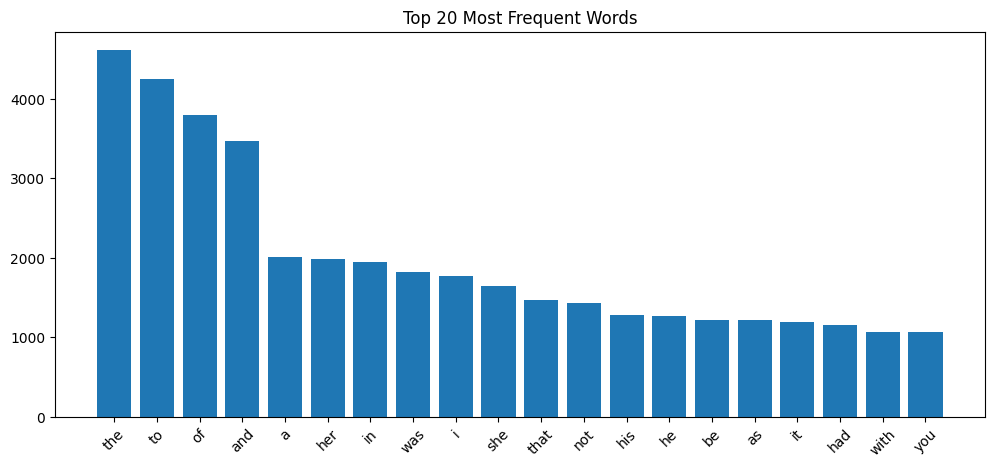

In [10]:
import matplotlib.pyplot as plt

top_words = word_counts.most_common(20)

labels = [x[0] for x in top_words]
values = [x[1] for x in top_words]

plt.figure(figsize=(12, 5))

plt.bar(labels, values)

plt.xticks(rotation=45)

plt.title("Top 20 Most Frequent Words")

plt.show()

In [11]:
os.makedirs("../data/interim", exist_ok=True)

cleaned_path = "../data/interim/cleaned_pride_prejudice.txt"

with open(cleaned_path, "w", encoding="utf-8") as file:
    file.write(cleaned_text)

print("Saved at:", os.path.abspath(cleaned_path))

Saved at: E:\data\interim\cleaned_pride_prejudice.txt


In [12]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

file_path = "../data/interim/cleaned_pride_prejudice.txt"

with open(file_path, "r", encoding="utf-8") as file:
    text = file.read()

print(text[:1000])

[Illustration:
 GEORGE ALLEN
 PUBLISHER
 156 CHARING CROSS ROAD
 LONDON
 RUSKIN HOUSE
 ]
 [Illustration:
 _Reading Jane’s Letters._ _Chap 34._
 ]
 PRIDE.
 and
 PREJUDICE
 by
 Jane Austen,
 with a Preface by
 George Saintsbury
 and
 Illustrations by
 Hugh Thomson
 [Illustration: 1894]
 Ruskin 156. Charing
 House. Cross Road.
 London
 George Allen.
 CHISWICK PRESS:--CHARLES WHITTINGHAM AND CO.
 TOOKS COURT, CHANCERY LANE, LONDON.
 [Illustration:
 _To J. Comyns Carr
 in acknowledgment of all I
 owe to his friendship and
 advice, these illustrations are
 gratefully inscribed_
 _Hugh Thomson_
 ]
PREFACE.
[Illustration]
_Walt Whitman has somewhere a fine and just distinction between “loving
by allowance” and “loving with personal love.” This distinction applies
to books as well as to men and women; and in the case of the not very
numerous authors who are the objects of the personal affection, it
brings a curious consequence with it. There is much more difference as
to their best work than in

In [13]:
words = text.split()

sentences = re.split(r'[.!?]+', text)

sentences = [
    sentence.strip()
    for sentence in sentences
    if sentence.strip()
]

print("Total words:", len(words))
print("Total sentences:", len(sentences))
print("Unique words:", len(set(words)))

Total words: 127360
Total sentences: 7357
Unique words: 14151


In [14]:
sentence_lengths = [
    len(sentence.split())
    for sentence in sentences
]

print("Average sentence length:", np.mean(sentence_lengths))
print("Maximum sentence length:", np.max(sentence_lengths))
print("Minimum sentence length:", np.min(sentence_lengths))
print("Median sentence length:", np.median(sentence_lengths))

Average sentence length: 17.503602011689548
Maximum sentence length: 145
Minimum sentence length: 1
Median sentence length: 13.0


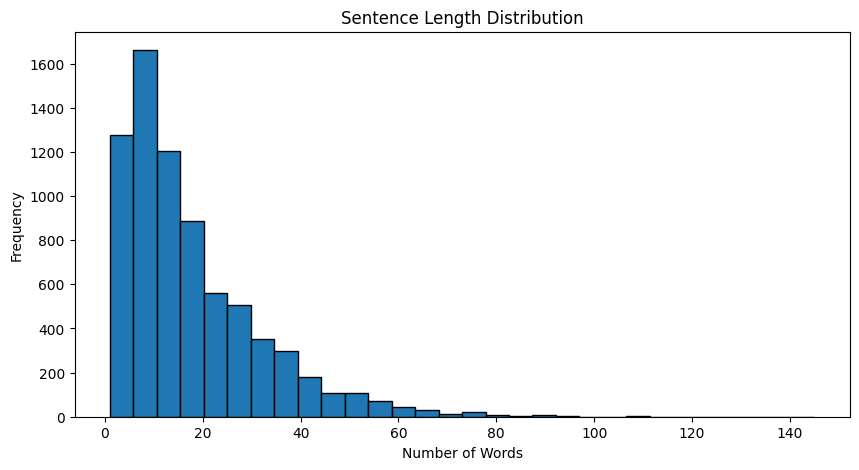

In [15]:
plt.figure(figsize=(10, 5))

plt.hist(
    sentence_lengths,
    bins=30,
    edgecolor='black'
)

plt.title("Sentence Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [16]:
from collections import Counter

word_counts = Counter(
    word.lower()
    for word in words
)

frequency_df = pd.DataFrame(
    word_counts.items(),
    columns=["Word", "Frequency"]
)

frequency_df = frequency_df.sort_values(
    by="Frequency",
    ascending=False
)

frequency_df.head(20)

,Word,Frequency
85,the,4613
54,to,4247
50,of,3795
18,and,3463
24,a,2004
283,her,1988
48,in,1942
333,was,1816
52,i,1764
456,she,1645


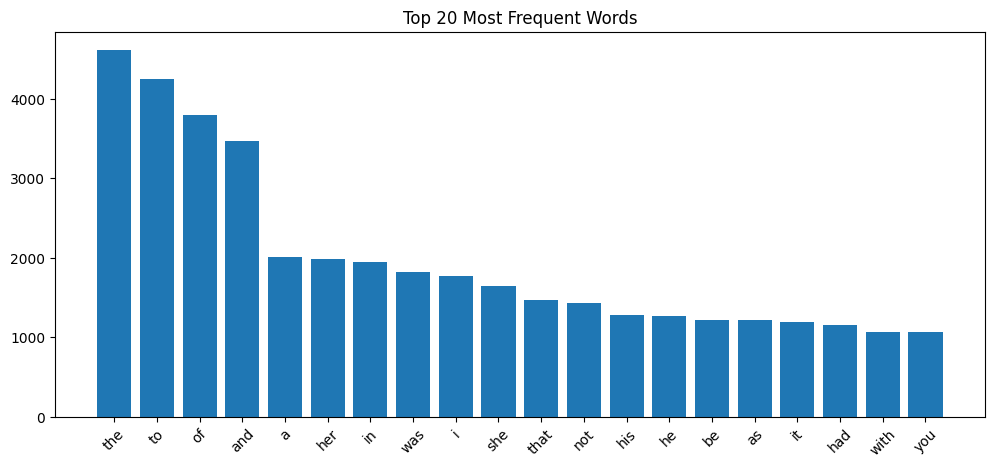

In [17]:
top_20 = frequency_df.head(20)

plt.figure(figsize=(12, 5))

plt.bar(
    top_20["Word"],
    top_20["Frequency"]
)

plt.xticks(rotation=45)
plt.title("Top 20 Most Frequent Words")

plt.show()

In [18]:
vocab_size = len(word_counts)

print("Vocabulary size:", vocab_size)

Vocabulary size: 13700


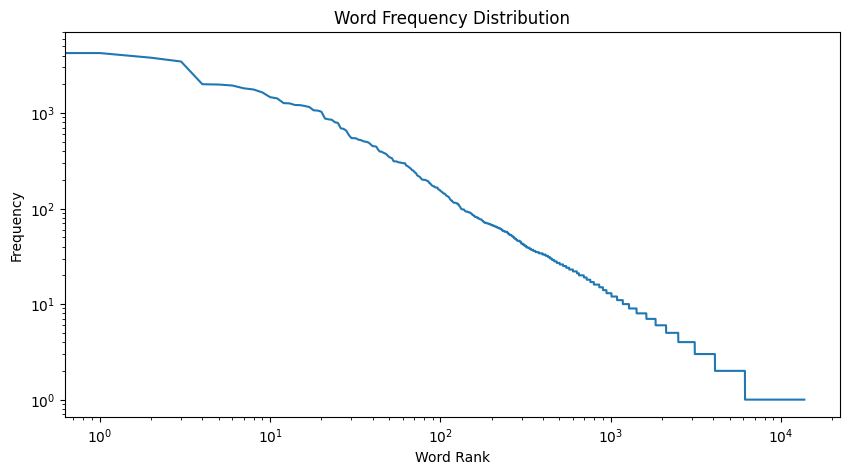

In [19]:
frequencies = sorted(
    word_counts.values(),
    reverse=True
)

plt.figure(figsize=(10, 5))

plt.plot(frequencies)

plt.title("Word Frequency Distribution")
plt.xlabel("Word Rank")
plt.ylabel("Frequency")

plt.yscale("log")
plt.xscale("log")

plt.show()

In [20]:
rare_words = [
    word
    for word, count in word_counts.items()
    if count == 1
]

print("Words appearing once:", len(rare_words))

print(rare_words[:50])

Words appearing once: 7565
['allen', 'publisher', '_reading', 'letters._', '_chap', '34._', 'saintsbury', 'hugh', 'thomson', '1894]', '156.', 'allen.', '_to', 'j.', 'comyns', 'carr', 'inscribed_', '_hugh', 'thomson_', 'preface.', '_walt', 'whitman', 'women;', 'authors', 'sect--fairly', 'unusually', 'choice--of', 'austenians', 'janites,', 'partisans', 'primacy', 'freshness', 'northanger', 'abbey,', '_its', 'completeness,', 'finish,', 'and_', 'entrain,', '_obscure', 'facts', 'burlesque', 'parody,', 'difficulty._', '_relatively', 'enthralling', 'devotees', 'exalt', 'exquisite', 'keeping.']


In [21]:
rare_percentage = (
    len(rare_words) / vocab_size
) * 100

print("Rare word percentage:", rare_percentage)

Rare word percentage: 55.21897810218979


In [22]:
paragraphs = [
    p.strip()
    for p in text.split("\n\n")
    if p.strip()
]

paragraph_counts = Counter(paragraphs)

duplicates = {
    paragraph: count
    for paragraph, count in paragraph_counts.items()
    if count > 1
}

print("Total paragraphs:", len(paragraphs))
print("Unique paragraphs:", len(paragraph_counts))
print("Duplicate paragraphs:", len(duplicates))

Total paragraphs: 1
Unique paragraphs: 1
Duplicate paragraphs: 0
